In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.linalg import cho_factor, cho_solve

In [2]:
def true_W(r):
    return -5.0 * np.maximum(1.0 - np.abs(r), 0.0)

def true_Wp(r):
    out = np.zeros_like(r)
    out[(r > -1.0) & (r < 0.0)] = 5.0
    out[(r > 0.0) & (r < 1.0)] = -5.0
    return out

# Differences
def dx_central(u, dx):
    out = np.zeros_like(u)
    out[1:-1] = (u[2:] - u[:-2]) / (2.0 * dx)
    out[0] = (u[1] - u[0]) / dx
    out[-1] = (u[-1] - u[-2]) / dx
    return out

def dt_central(rho, dt):
    out = np.zeros_like(rho)
    out[1:-1] = (rho[2:] - rho[:-2]) / (2.0 * dt)
    out[0] = (rho[1] - rho[0]) / dt
    out[-1] = (rho[-1] - rho[-2]) / dt
    return out

def rbf_kernel(r, s, ell):
    return np.exp(-(r - s) ** 2 / (2.0 * ell**2))

# Recover W by flux inversion
def recover_W_by_flux(rho, x, t, params):
    dx = x[1] - x[0]
    dt = t[1] - t[0]
    m = params["m"]
    kappa = params["kappa"]
    num_centers = params["num_centers"]
    ell = params["ell"]
    lam = params["lam"]
    rho_cut = params["rho_cut"]
    r_max_fit = params["r_max_fit"]
    r_max_plot = params.get("r_max_plot", r_max_fit)
    num_plot_points = params["num_plot_points"]
    Ltime, N = rho.shape
    R = x[:, None] - x[None, :]
    centers = np.linspace(0.02, r_max_fit, num_centers)
    J = len(centers)
    rho_t = dt_central(rho, dt)
    rows = []
    vals = []
    weights = []
    for l in range(1, Ltime - 1):
        rho_l = rho[l]
        internal = kappa * rho_l ** (m - 1)
        internal_x = dx_central(internal, dx)
        internal_flux = rho_l * internal_x
        internal_rhs = dx_central(internal_flux, dx)
        f = rho_t[l] - internal_rhs
        q_edge = np.zeros(N + 1)
        q_edge[1:] = np.cumsum(dx * f)
        drift = np.linspace(0.0, q_edge[-1], N + 1)
        q_edge -= drift
        q_center = 0.5 * (q_edge[:-1] + q_edge[1:])
        mask = rho_l > rho_cut
        y_l = q_center[mask] / rho_l[mask]
        M_l = np.zeros((np.sum(mask), J))
        for j, s in enumerate(centers):
            basis = (rbf_kernel(R, s, ell) - rbf_kernel(R, -s, ell))
            conv_basis = dx * (basis @ rho_l)
            M_l[:, j] = conv_basis[mask]
        rows.append(M_l)
        vals.append(y_l)
        weights.append(rho_l[mask])
    M = np.vstack(rows)
    y = np.concatenate(vals)
    w = np.concatenate(weights)
    sw = np.sqrt(w)
    Mw = M * sw[:, None]
    yw = y * sw
    S = Mw.T @ Mw
    b = Mw.T @ yw
    A = S + lam * np.eye(J)
    print("training samples =", M.shape[0])
    print("unknowns =", J)
    print("lambda =", lam)
    print("cond(A) =", np.linalg.cond(A))
    cf = cho_factor(A + 1e-12 * np.eye(J), lower=True)
    beta = cho_solve(cf, b)
    r_plot = np.linspace(-r_max_plot, r_max_plot, num_plot_points)
    Wp = np.zeros_like(r_plot)
    for bj, s in zip(beta, centers):
        Wp += bj * (rbf_kernel(r_plot, s, ell) - rbf_kernel(r_plot, -s, ell))
    W_hat = np.zeros_like(r_plot)
    mid = len(r_plot) // 2
    for i in range(mid + 1, len(r_plot)):
        dr = r_plot[i] - r_plot[i - 1]
        W_hat[i] = W_hat[i - 1] + 0.5 * (Wp[i] + Wp[i - 1]) * dr
    for i in range(mid - 1, -1, -1):
        dr = r_plot[i + 1] - r_plot[i]
        W_hat[i] = W_hat[i + 1] - 0.5 * (Wp[i] + Wp[i + 1]) * dr
    W_hat = 0.5 * (W_hat + W_hat[::-1])
    return {
        "r_plot": r_plot,
        "W_hat": W_hat,
        "Wp_hat": Wp,
        "beta": beta,
        "centers": centers,
        "M_shape": M.shape,
        "cond_A": np.linalg.cond(A),
    }

def relative_L2_error(f_hat, f_true, mask):
    return (
        np.linalg.norm(f_hat[mask] - f_true[mask])
        /
        np.linalg.norm(f_true[mask])
    )

Dataset = example1_Cx6_Ct50
rho shape = (201, 200)
dx = 0.05999999999999961
dt = 0.0025
m = 2
kappa = 0.2
Cx = 6
Ct = 50
Delta_x = 0.06
Delta_t = 0.0025
training samples = 11922
unknowns = 80
lambda = 0.01
cond(A) = 278004.99645721173
[-2,2] : W = 2.6573e-02, W' = 1.9276e+00
[-4,4] : W = 2.7073e-02, W' = 1.9276e+00
[-6,6] : W = 2.7305e-02, W' = 1.9276e+00


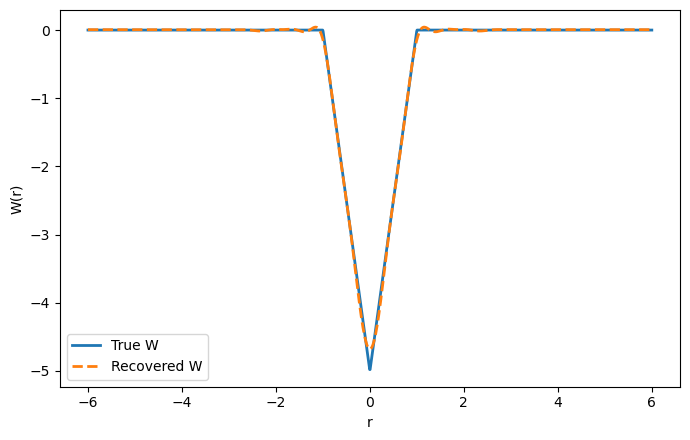

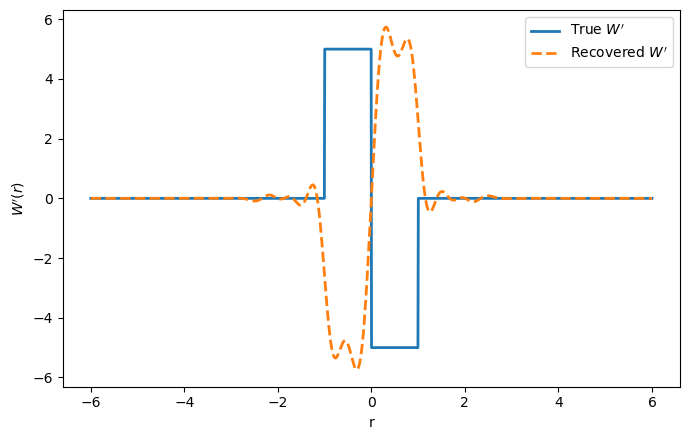

In [6]:
# Example 1: flux inversion with kernel method

# Parameters
params = {
    "data_file": "example1_Cx6_Ct50.npz",
    "m": 2,
    "kappa": 0.2,
    "num_centers": 80,
    "ell": 0.2,
    "lam": 1e-2,
    "rho_cut": 1e-5,
    "r_max_fit": 2.5,
    "r_max_plot": 6.0,
    "num_plot_points": 1500,
}

data = np.load(params["data_file"])
tag = os.path.splitext(os.path.basename(params["data_file"]))[0]
x = data["x_obs"]
t = data["obs_times"]
rho = data["obs_snapshots"]
m = int(data["m"])
kappa = float(data["kappa"])
print("Dataset =", tag)
print("rho shape =", rho.shape)
print("dx =", x[1] - x[0])
print("dt =", t[1] - t[0])
print("m =", m)
print("kappa =", kappa)

if "Cx" in data:
    print("Cx =", int(data["Cx"]))
if "Ct" in data:
    print("Ct =", int(data["Ct"]))
if "Delta_x" in data:
    print("Delta_x =", float(data["Delta_x"]))
if "Delta_t" in data:
    print("Delta_t =", float(data["Delta_t"]))

# Run estimator
result = recover_W_by_flux(rho, x, t, params)
r_plot = result["r_plot"]
W_hat_raw = result["W_hat"]
Wp_hat = result["Wp_hat"]
W_ref  = true_W(r_plot)
Wp_ref = true_Wp(r_plot)
for R in [2, 4, 6]:
    mask = np.abs(r_plot) <= R
    W_hat = W_hat_raw + np.mean(W_ref[mask] - W_hat_raw[mask])
    print(
        f"[-{R},{R}] : "
        f"W = {relative_L2_error(W_hat, W_ref, mask):.4e}, "
        f"W' = {relative_L2_error(Wp_hat, Wp_ref, mask):.4e}"
    )

# save figures
os.makedirs("figures_kernel_flux", exist_ok=True)
plt.figure(figsize=(7, 4.5))
plt.plot(r_plot, W_ref, label="True W", linewidth=2)
plt.plot(r_plot, W_hat, "--", label="Recovered W", linewidth=2)
plt.xlabel("r")
plt.ylabel("W(r)")
plt.legend()
plt.tight_layout()
plt.savefig(f"figures_kernel_flux/{tag}_flux_recovered_W.png", dpi=300, bbox_inches="tight",)
plt.savefig(f"figures_kernel_flux/{tag}_flux_recovered_W.pdf", bbox_inches="tight",)
plt.show()


plt.figure(figsize=(7, 4.5))
plt.plot(r_plot, Wp_ref, label="True $W'$", linewidth=2)
plt.plot(r_plot, Wp_hat, "--", label="Recovered $W'$", linewidth=2)
plt.xlabel("r")
plt.ylabel(r"$W'(r)$")
plt.legend()
plt.tight_layout()
plt.savefig(f"figures_kernel_flux/{tag}_flux_recovered_Wprime.png", dpi=300, bbox_inches="tight",)
plt.savefig( f"figures_kernel_flux/{tag}_flux_recovered_Wprime.pdf", bbox_inches="tight",)
plt.show()